# Differential abundance with Milo and MELD

*Python port of the R vignette [Differential abundance with Milo and MELD](https://gregorlueg.github.io/bixverse/articles/differential_abundance.html). Original author: Gregor Lueg.*

## Intro

Differential expression asks whether cells changed what they express.
Differential abundance asks whether the cells that are there changed at all.
Both matter, and the second is the one people usually answer badly.

The obvious approach is to cluster, count cells per cluster per sample, and
test the proportions. It works, and it inherits every problem the clustering
had. If a condition shifts a subpopulation that your resolution parameter
merged into a bigger cluster, you see nothing. If it shifts half a cluster, the
proportion barely moves. The answer depends on a choice you made before you
asked the question.

Two methods here avoid that, in different ways.

[Milo](https://doi.org/10.1038/s41587-021-01033-z) tests overlapping
neighbourhoods of the kNN graph instead of clusters. Each neighbourhood is a
cell and its neighbours, so the resolution is the graph's rather than the
clustering's, and a shift that spans part of a cluster shows up. Counts per
neighbourhood per sample go through the same negative binomial machinery bulk
RNA-seq uses.

[MELD](https://doi.org/10.1038/s41587-020-00803-5) does not test anything. It
smooths the condition labels over the graph and returns, per cell, how likely
that cell is under each condition. It is a continuous score rather than a set
of calls, which suits a graded response better than a discrete one.

They answer the same question and they should agree. At the end of this
vignette they do, which is a better check on both than either provides alone.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

import bixverse as bv
import bixverse.embed
from bixverse.params import MinQualityParams, NeighboursParams

## The data

[Baran-Gale, et al.](https://doi.org/10.1242/dev.183996) profiled mouse thymic
epithelial cells at one, four and sixteen weeks. The thymus involutes with age,
so the cell type proportions genuinely move, which is what makes this a
sensible differential abundance example.

> **A stimulation experiment is a bad Milo example**
>
> It is tempting to reuse a treatment dataset here. Do not. In vitro
> stimulation moves cells a long way in embedding space without moving the
> cell type proportions much, so stimulated and control cells separate into
> different neighbourhoods and almost every neighbourhood comes out
> significant. The result looks spectacular and says nothing beyond "the
> treatment did something", which you knew.
>
> Differential abundance needs a design where the *composition* plausibly
> changed.

The download is an h5ad with the raw counts in `X`, the cell annotations in
obs and the Ensembl identifiers as var index. 336 genes have no annotation
whatsoever and carry a generated `unannotated_<row>` identifier.

In [2]:
# the per cell type tables further down have 23 rows, show them in full
pl.Config.set_tbl_rows(25)

thymus_path = bv.io.download_thymus_ageing()

tempdir_thymus = tempfile.TemporaryDirectory()

sc = bv.io.load_h5ad(
    Path(tempdir_thymus.name) / "thymus",
    thymus_path,
    qc=MinQualityParams(
        min_unique_genes=200,
        min_lib_size=500,
        min_cells=20,
        target_size=1e4,
    ),
    verbose=True,
)

sc

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading CSR matrix structure (shape: 69_180 x 31_053 )...
First pass - gene expression statistics:


  Processed 10% of chunks (1/7)
  Processed 30% of chunks (2/7)
  Processed 40% of chunks (3/7)
  Processed 60% of chunks (4/7)


  Processed 70% of chunks (5/7)
  Processed 90% of chunks (6/7)
  Processed 100% of chunks (7/7)
  Gene expression stats: min = 0 | max = 69_180 | avg = 8_028 cells per gene
First pass done: 541.47ms
  Genes passing filter: 22_719 / 31_053
Second pass - cell statistics:


  Processed 10% of chunks (1/7)
  Processed 30% of chunks (2/7)
  Processed 40% of chunks (3/7)
  Processed 60% of chunks (4/7)
  Processed 70% of chunks (5/7)
  Processed 90% of chunks (6/7)


  Processed 100% of chunks (7/7)
  Cell stats: genes per cell: min = 1_276 | max = 9_396
  Cell stats: library size: min = 4240.0 | max = 120783.0
Second pass done: 1.16s
  Cells passing filter: 69_180 / 69_180
Step 2/3: QC Results:
  Genes passing QC: 22_719 / 31_053
  Cells passing QC: 69_180 / 69_180
Step 3/3: Writing cells to CSR format...
  Processing 69_180 cells in batches of 1_000...
  Processed 1_000 / 69_180 cells
  Processed 8_000 / 69_180 cells


  Processed 15_000 / 69_180 cells
  Processed 22_000 / 69_180 cells


... (2 outputs left out)

  Processed 57_000 / 69_180 cells
  Processed 64_000 / 69_180 cells
  Processed 69_180 / 69_180 cells
  Writing complete in 1.10s
Converting the cell-based data into the gene-based format.


  Counted 249_283_013 non-zeros over 22_719 genes in 98.36ms; converting in 1 phase(s).


  Phase 1/1: genes 0-22719, scatter 324.47ms, compress + write 347.66ms
  Conversion into gene-friendly format done: 772.34ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmp_mtjtdf3/thymus',
  cells=69180 (kept 69180), genes=22719,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

Now the design, and there is a trap in it. `samp_id` looks like the sample. It
is not: it is the sequencing run, and every run carries all three ages, because
the ages were hashed together and demultiplexed.

In [3]:
obs = sc.obs(filtered=True)

obs.group_by("samp_id", "age").len().sort("age").pivot(
    on="age", index="samp_id", values="len"
).sort("samp_id")

samp_id,Wk1,Wk4,Wk16
enum,u32,u32,u32
"""1stRun1""",5160,3902,3798
"""1stRun2""",3360,2355,4199
"""2ndRun1""",4017,4629,3728
"""2ndRun2""",3897,4551,3630
"""3rdRun1""",3263,3771,2981
"""3rdRun2""",3745,4910,3284


The sample is the run and the age together, which gives eighteen. Using
`samp_id` as the sample would ask Milo whether abundance differs between
sequencing runs, and every run contains every age, so the answer would be a
flat no.

In [4]:
sc.add_obs(
    obs.select(
        "cell_idx",
        pl.concat_str(["samp_id", "age"], separator="_").alias("sample"),
    )
)
obs = sc.obs(filtered=True)

obs.group_by("sample", "age").len().sort("age").pivot(
    on="age", index="sample", values="len"
).fill_null(0).sort("sample").head(6)

sample,Wk1,Wk4,Wk16
str,u32,u32,u32
"""1stRun1_Wk1""",5160,0,0
"""1stRun1_Wk16""",0,0,3798
"""1stRun1_Wk4""",0,3902,0
"""1stRun2_Wk1""",3360,0,0
"""1stRun2_Wk16""",0,0,4199
"""1stRun2_Wk4""",0,2355,0


## The embedding

Milo and MELD both run on the kNN graph, so the usual pipeline comes first.

In [5]:
bv.pp.find_hvg(sc, hvg_no=2000)

bv.pp.calculate_pca(sc, no_pcs=30)

HVG (VST): 22_719 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 151.64ms
HVG (VST): Fitted Loess in 900.00µs
HVG (VST): Standardised variance in 2.02ms (1_342 gene(s) re-read for the clip)
HVG (VST): Total run time -> 154.61ms
Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 45.93ms
Sparse PCA: finished the data preparations in 5.96ms


Sparse PCA: finished calculations in 400.93ms
Sparse PCA: total run time -> 453.56ms


The default `k` of 15 is fine for clustering and too small for Milo. A
neighbourhood is the index cell, its `k` neighbours and every cell that lists it
as a neighbour, so it holds at least `k + 1` cells, and those get spread over
the samples. With eighteen samples and `k = 15` the smallest neighbourhoods have
under one cell per sample, and a negative binomial fitted to counts that are
mostly zero or one has very little to work with.

Rough rule: pick `k` so the average neighbourhood holds at least a few cells
per sample. Eighteen samples and `k = 60` gives around eight here, the
neighbourhoods averaging just under 150 cells.

In [6]:
bv.graph.find_neighbours(sc, neighbours_params=NeighboursParams(k=60), verbose=True)

Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 125.89ms
Generated KmKnn index: 133.32ms
Querying kMkNN index (self) ...


... queried kMkNN index (self) in 963.19ms
Queried KmKnn index: 963.59ms
Generating the snn graph.


Added 1 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 347.42ms


## Milo

Sampling the neighbourhoods and counting the cells per sample is one call. The
counts come back as neighbourhoods by samples, with the graph-overlap weighting
and the k-th neighbour distances taken at the same time, since all three are
functions of the neighbourhood matrix alone.

In [7]:
milo = bv.de.get_milor_abundances(
    sc,
    "sample",
    milor_params=bv.de.MiloRParams(prop=0.1),
    verbose=True,
)
assert milo is not None

print(milo.sample_counts.shape)
print(milo.sample_counts.sum(axis=1).mean())

Sampled 6918 vertices from 69180 cells
Running refined sampling
Refined to 5191 unique neighbourhood indices
(5191, 18)
146.50260065497977


The test needs a design table with one row per sample and a column holding the
sample names that match the columns of the counts. Blocking on the run is
worth it: every run contributes all three ages, so run-to-run variation is a
nuisance term the model can remove.

In [8]:
design_df = pl.DataFrame({"sample": milo.samples}).join(
    obs.select("sample", pl.col("samp_id").alias("run"), "age").unique(),
    on="sample",
    how="left",
    maintain_order="left",
)

design_df.group_by("age", "run").len().sort("run").pivot(
    on="run", index="age", values="len"
).sort("age")

age,1stRun1,1stRun2,2ndRun1,2ndRun2,3rdRun1,3rdRun2
enum,u32,u32,u32,u32,u32,u32
"""Wk1""",1,1,1,1,1,1
"""Wk4""",1,1,1,1,1,1
"""Wk16""",1,1,1,1,1,1


> **Check which coefficient you are testing**
>
> `test_nhoods()` defaults to the last column of the design, the way edgeR and
> limma do. Which level ends up last depends on the level order of `age`. An
> Enum keeps its own order, and `age` comes out of the h5ad as one ordered
> `Wk1`, `Wk4`, `Wk16`, so here the default happens to be right. Cast it to a
> plain string and the levels get sorted: `Wk1`, `Wk16`, `Wk4`. The last
> coefficient is then **Wk4 against Wk1**, not the sixteen week contrast you
> probably wanted.
>
> Name the coefficient rather than trusting the default.

In [9]:
milo = bv.de.test_nhoods(
    milo,
    "~ run + age",
    design_df,
    sample_col="sample",
    coef="ageWk16",
)

da_res = bv.de.get_differential_abundance_res(milo)
assert da_res is not None

da_res.filter(pl.col("SpatialFDR") <= 0.1).height

3135

In [10]:
da_res.sort("PValue").select("Nhood", "logFC", "F", "PValue", "FDR", "SpatialFDR").head(
    6
)

Nhood,logFC,F,PValue,FDR,SpatialFDR
i64,f64,f64,f64,f64,f64
4499,3.669117,85.82945,1.0119e-13,2.3761e-10,1.6727e-10
2166,3.334926,84.1043,1.4950e-13,2.3761e-10,1.6727e-10
1420,3.947703,84.015014,1.5257e-13,2.3761e-10,1.6727e-10
2899,3.455329,83.215046,1.8314e-13,2.3761e-10,1.6727e-10
3720,2.955785,82.19818,2.3132e-13,2.3761e-10,1.6727e-10
2403,-3.491821,81.455195,2.7464e-13,2.3761e-10,1.6727e-10


A neighbourhood is not a cell type, so on its own a list of neighbourhood
indices is not much use. `add_nhoods_info()` tags each with the cell type its
cells mostly belong to.

In [11]:
milo = bv.de.add_nhoods_info(milo, cell_info=obs["cluster_annot"])
da_res = bv.de.get_differential_abundance_res(milo)
assert da_res is not None

sig = da_res.filter(pl.col("SpatialFDR") <= 0.1).with_columns(
    direction=pl.when(pl.col("logFC") > 0)
    .then(pl.lit("up at Wk16"))
    .otherwise(pl.lit("down at Wk16"))
)

(
    sig.group_by("majority_celltype", "direction")
    .len()
    .pivot(on="direction", index="majority_celltype", values="len")
    .fill_null(0)
    .sort("up at Wk16", descending=True)
)

majority_celltype,up at Wk16,down at Wk16
str,u32,u32
"""Intertypical.TEC.1""",381,576
"""Intertypical.TEC.2""",347,48
"""Intertypical.TEC.4""",343,184
"""Intertypical.TEC.3""",230,46
"""mTEC.2""",55,157
"""cTEC.2""",49,46
"""mTEC.1""",22,254
"""mTEC.4""",20,0
"""mTEC.3""",17,0


The two proliferating populations are the most strongly depleted of anything
here, which is the clearest ageing signal the tissue has: an involuting thymus
stops making new cells. The intertypical TECs dominate the enriched side.

The medullary subsets split both ways, so "mTECs go up" would be the wrong
summary to take away. That is the point of testing neighbourhoods rather than
clusters: a cluster level test would have averaged those subsets into one
number and reported whichever direction happened to win.

### On the embedding

The figure everyone expects from Milo is the neighbourhood graph on a UMAP.
Each neighbourhood sits at its index cell, sized by how many cells it holds and
connected to the neighbourhoods it shares cells with. Significant ones are
coloured by logFC, the rest stay white. The UMAP is only for the picture, the
test above never touched it.

In [12]:
bv.embed.umap(sc)

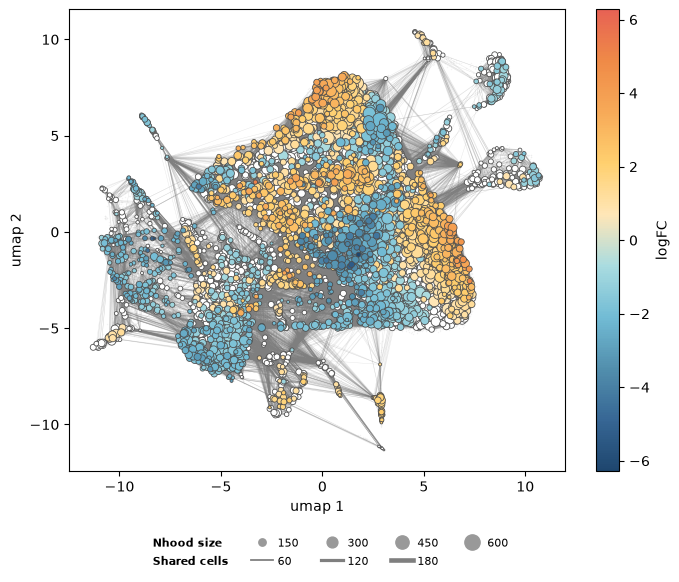

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
bv.pl.milo_nhood_plot(sc, milo, embedding="umap", alpha=0.1, ax=ax)
plt.show()

`colour_by="majority_celltype"` swaps the logFC for the annotation from
`add_nhoods_info()`, which helps to read the logFC plot next to it.

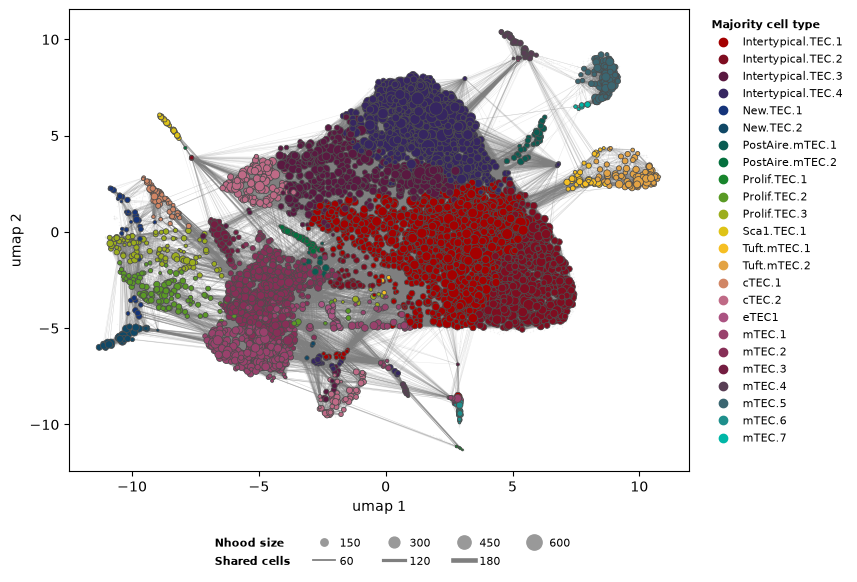

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
bv.pl.milo_nhood_plot(sc, milo, embedding="umap", colour_by="majority_celltype", ax=ax)
plt.show()

The nodes and edges behind the plot come from `extract_milo_plot_data`, if
you want to draw them yourself.

In [15]:
milo_plot_data = bv.pl.extract_milo_plot_data(sc, milo, embedding="umap")

milo_plot_data.nodes.select("Nhood", "dim_1", "dim_2", "size", "is_sig").head()

Nhood,dim_1,dim_2,size,is_sig
i64,f64,f64,f64,bool
0,3.984179,-3.980668,83.0,false
1,2.841785,-8.60739,164.0,true
2,1.699454,2.853889,213.0,true
3,-3.89443,-6.013515,125.0,true
4,2.9168,-8.736634,159.0,true


### On the spatial FDR

Neighbourhoods overlap, so their tests are not independent and a plain
Benjamini-Hochberg adjustment is anti-conservative. Milo's spatial FDR weights
each p-value by the reciprocal of its connectivity and runs the step-up on
those weights.

In [16]:
pl.DataFrame(
    {
        "plain_fdr": [da_res.filter(pl.col("FDR") <= 0.1).height],
        "spatial_fdr": [da_res.filter(pl.col("SpatialFDR") <= 0.1).height],
    }
)

plain_fdr,spatial_fdr
i64,i64
3109,3135


On this data the two barely differ. That is worth knowing rather than
disappointing: the correction bites when neighbourhoods overlap heavily and the
connectivity varies a lot between them, and here it does not. Do not assume it
is always doing work.

The weighting scheme is a choice. `"k-distance"` weights by the distance to the
k-th neighbour, `"graph-overlap"` by how many cells a neighbourhood shares with
the others. Both are precomputed, so switching is cheap.

## MELD

MELD needs no design and no neighbourhood sampling. Hand it the condition
column and it smooths the indicator over the graph.

In [17]:
meld_res = bv.de.meld(sc, "age")
assert meld_res is not None

print(meld_res.norm_scores.shape)
meld_res.norm_scores.head(4).with_columns(pl.selectors.numeric().round(3))

MELD: building kernel adjacency from kNN (69_180 cells)...
 Done in 184.93ms
MELD: building Laplacian...


 Done in 395.72ms
MELD: estimating largest Laplacian eigenvalue...
MELD: lmax = 258.8170
 Done in 469.11ms
MELD: applying Chebyshev filter (order=50) to 3 signals...


 Done in 771.08ms
MELD: done in 771.09ms
(69180, 4)


cell_id,Wk1,Wk4,Wk16
str,f64,f64,f64
"""Ageing_ZsG_1stRun1_HTO_AAACCCA…",0.298,0.315,0.387
"""Ageing_ZsG_1stRun1_HTO_AAACCCA…",0.495,0.323,0.182
"""Ageing_ZsG_1stRun1_HTO_AAACCCA…",0.345,0.302,0.353
"""Ageing_ZsG_1stRun1_HTO_AAACCCA…",0.196,0.308,0.496


The normalised scores are clamped at zero and L1 normalised per cell, so each
row is a likelihood over the three ages. A cell sitting at 0.6 for Wk16 lives
in a part of the manifold that is enriched for sixteen week old thymus.

Averaging per cell type turns that into something readable.

In [18]:
per_celltype = (
    meld_res.norm_scores.drop("cell_id")
    .with_columns(cluster=obs["cluster_annot"].cast(pl.String))
    .group_by("cluster")
    .mean()
)

per_celltype.sort("Wk16", descending=True).head(8)

cluster,Wk1,Wk4,Wk16
str,f64,f64,f64
"""mTEC.6""",0.177081,0.254674,0.568246
"""mTEC.4""",0.285559,0.281088,0.433353
"""Intertypical.TEC.2""",0.270317,0.324893,0.40479
"""Intertypical.TEC.4""",0.305711,0.297408,0.396881
"""New.TEC.2""",0.301034,0.306503,0.392463
"""mTEC.3""",0.325436,0.306169,0.368396
"""Intertypical.TEC.3""",0.287727,0.347549,0.364724
"""New.TEC.1""",0.37123,0.265781,0.362989


## Do they agree

They are different methods on the same graph, so this is a real check rather
than a formality. Milo's mean log fold change per cell type against MELD's mean
Wk16 likelihood per cell type.

In [19]:
milo_per_ct = sig.group_by(pl.col("majority_celltype").alias("cluster")).agg(
    milo_logfc=pl.col("logFC").mean()
)
comparison = per_celltype.join(milo_per_ct, on="cluster")

comparison.sort("milo_logfc", descending=True).select(
    "cluster", "Wk1", "Wk16", "milo_logfc"
)

cluster,Wk1,Wk16,milo_logfc
str,f64,f64,f64
"""mTEC.6""",0.177081,0.568246,1.793727
"""Intertypical.TEC.2""",0.270317,0.40479,1.591154
"""mTEC.3""",0.325436,0.368396,1.372783
"""Intertypical.TEC.3""",0.287727,0.364724,1.289313
"""mTEC.4""",0.285559,0.433353,1.097228
"""eTEC1""",0.33533,0.346904,0.965001
"""New.TEC.2""",0.301034,0.392463,0.928169
"""Intertypical.TEC.4""",0.305711,0.396881,0.64396
"""cTEC.2""",0.305612,0.337303,0.140871


In [20]:
comparison.select(pl.corr("Wk16", "milo_logfc", method="spearman")).item()

0.8853754940711462

Strong agreement, and the disagreements are informative rather than
embarrassing. Milo tests neighbourhoods and reports only the ones that clear a
threshold, so a cell type that shifted a little everywhere can score low on the
Milo axis while MELD still registers the shift. The two are measuring related
but not identical things.

## Which one to reach for

Milo when you want calls with error control: a list of regions that changed,
with p-values you can defend and a multiple testing correction that accounts
for the overlap. It needs a real design, enough samples to fit a negative
binomial, and a `k` large enough that the counts are not mostly zero.

MELD when the response is graded, when you want a per-cell score to carry into
downstream analysis, or when the design is too thin for a test. It gives you no
p-values, which is a feature when you have four samples and would only have
been fooling yourself.

Running both costs almost nothing once the graph is built, and their agreement
is the most useful diagnostic either one has.

## Where next

The other half of this is differential *expression* with the same donor
structure, which has its own [vignette](differential_expression.ipynb).
Neighbourhood level expression testing, rather than abundance, is not wired up
yet.

## Clean up

In [21]:
tempdir_thymus.cleanup()